In [3]:
import numpy as np
import matplotlib.pyplot as plt
import utils

from os.path import exists
import json 
import pymultinest
plt.style.use('/home/adiaz/Plots/thesis.mplstyle')

In [4]:
logdm2_list = np.asarray(np.ndarray.tolist(np.arange(-2.10, 2.10, 0.1))+ [2.15])
dm2_list = np.power(10, logdm2_list)  
dm2_list = dm2_list[np.logical_and(dm2_list>.1, dm2_list<50)]
dm2_list = np.append(dm2_list, 50.0)

log_Um4sq_list = np.asarray(np.ndarray.tolist(np.arange(-3., 0., 0.1)))  
Um4sq_list = np.power(10, log_Um4sq_list)
Um4sq_list = Um4sq_list[Um4sq_list<0.50]
Um4sq_list = np.append(Um4sq_list, 0.50)

log_Ut4sq_list = np.asarray(np.ndarray.tolist(np.arange(-3., 0., 0.2)))   
Ut4sq_list = np.power(10, log_Ut4sq_list)  
Ut4sq_list = np.insert(Ut4sq_list, 0, 0.)
Ut4sq_list = Ut4sq_list[Ut4sq_list<0.50]
Ut4sq_list = np.append(Ut4sq_list, 0.50)

d24_list = [np.pi]

In [3]:
# def get_llh(filename):
    
#     f = open(filename, 'r')
    
#     try:
#         data = json.loads(f.read())
#         llh =  data["BayesEvidence"]
#     except json.decoder.JSONDecodeError:
#         print("DecodeError, filename is {}".format(filename))
#         llh = np.inf

    
#     f.close()
    
#     return llh

In [4]:
# u_dir = "/data/ana/SterileNeutrino/IC86/HighEnergy/Analysis/th34/Fits/FitToData/Bayes/"


# null = get_llh(u_dir + "Ut4sq_{:.6f}/".format(0.) +  "{:.6f}_{:.6f}_{:.6f}.json".format(0,0,0))

In [5]:
# data = np.array(len(Ut4sq_list)*[[[0,0,0,-np.inf]]*len(dm2_list)*len(Um4sq_list)*len(d24_list)])
# for k, Ut4sq in enumerate(Ut4sq_list):
#     i=0

#     Ut4sq_dir = u_dir + "Ut4sq_" + str(format(float(Ut4sq), '.6f')) +'/'
#     for d24 in d24_list:
#         for dm2 in dm2_list:
#             for Um4sq in Um4sq_list:

#                 if Um4sq + Ut4sq > 1.:
#                     i+=1
#                     continue 

#                 th24 = np.arcsin( np.sqrt(Um4sq) )
#                 th34 = np.arcsin( np.sqrt(Ut4sq/np.cos(th24)**2) )
#                 point = "{:.6f}_{:.6f}_{:.6f}".format(dm2, th24, th34)
#                 suffix = ".json"
# #                     print(point)
#                 if exists(Ut4sq_dir + point+suffix):             
#                     llh = get_llh(Ut4sq_dir + point+suffix)
#                     data[k][i] = [dm2, Um4sq, Ut4sq, llh]
#                 else: 
#                     # print(Ut4sq_dir + point+suffix)
#                     data[k][i] = [dm2, Um4sq, Ut4sq, -np.inf]

#                 i+=1
                


In [13]:
dir_name = "/data/ana/SterileNeutrino/IC86/HighEnergy/Analysis/th34/Fits/FitToData/AIRS_mceq121_2011_sib_HG_E3/Bayes/evidence_tolerance_0.5_n_live_points_300_sampling_efficiency_0.5_crSlopeWidth_0.25/"
data = np.load(dir_name + "bayes_evidence_tolerance_0.5_n_live_points_300_sampling_efficiency_0.5_crSlopeWidth_0.25.npy")
data_null = np.load(dir_name + "bayes_evidence_tolerance_0.5_n_live_points_300_sampling_efficiency_0.5_crSlopeWidth_0.25_null.npy")

In [14]:
# data = np.load("/home/adiaz/Cascades/th34/FitsToData/Bayes/bayes_evidence_tolerance_0.5_n_live_points_300_sampling_efficiency_0.5_Run2.npy")
# data_null = np.load("/home/adiaz/Cascades/th34/FitsToData/Bayes/bayes_evidence_tolerance_0.5_n_live_points_300_sampling_efficiency_0.5_Run2_null.npy")

In [15]:
arg_max = np.unravel_index(data[:,:,3].argmax(), data[:,:,3].shape)
dm2_max, Um4sq_max, Ut4sq_max, llh_max =data[arg_max]
x_maxs = [Um4sq_max, utils.Um4sqtosin22th(Um4sq_max)]
th14_max, th24_max, th34_max = utils.Usq_to_thetas(0.,Um4sq_max, Ut4sq_max)
print(dm2_max, Um4sq_max, Ut4sq_max, llh_max)
print(th14_max, th24_max, th34_max)
print(utils.Um4sqtosin22th(Um4sq_max))
print("{:.6f}_{:.6f}_{:.6f}".format(dm2_max, th24_max, th34_max))
print(utils.get_point_string(dm2 = dm2_max, th24=th24_max, th34=th34_max, d24 = np.pi))

1.2589254117941726 0.0012589254117941675 0.001 -2922.059770218961
0.0 0.035488787870616524 0.03164798358621141
0.005029362074406825
1.258925_0.035489_0.031648
0_1.258925_0.000000_0.035489_0.031648_0.000000_3.141593


In [10]:
np.log10(np.exp(1.))

0.4342944819032518

In [11]:
(-(data[:,:,3]-data_null[3]) * np.log10(np.exp(1.))).min()

-2.9739520570640194

In [6]:
data[arg_max][3] = -np.inf

/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_7_x86_64/lib/python3.7/site-packages/matplotlib/contour.py:1230: UserWarning: No contour levels were found within the data range.
  warnings.warn("No contour levels were found"
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_7_x86_64/lib/python3.7/site-packages/matplotlib/contour.py:1540: UserWarning: Warning: converting a masked element to nan.
  self.zmax = float(z.max())
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_7_x86_64/lib/python3.7/site-packages/matplotlib/contour.py:1541: UserWarning: Warning: converting a masked element to nan.
  self.zmin = float(z.min())
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_7_x86_64/lib/python3.7/site-packages/matplotlib/contour.py:1226: RuntimeWarning: invalid value encountered in greater
  inside = (self.levels > self.zmin) & (self.levels < self.zmax)
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_7_x86_64/lib/python3.7/site-packages/matplotlib/contour.py:1226: RuntimeWarning: 

UnboundLocalError: local variable 'c' referenced before assignment

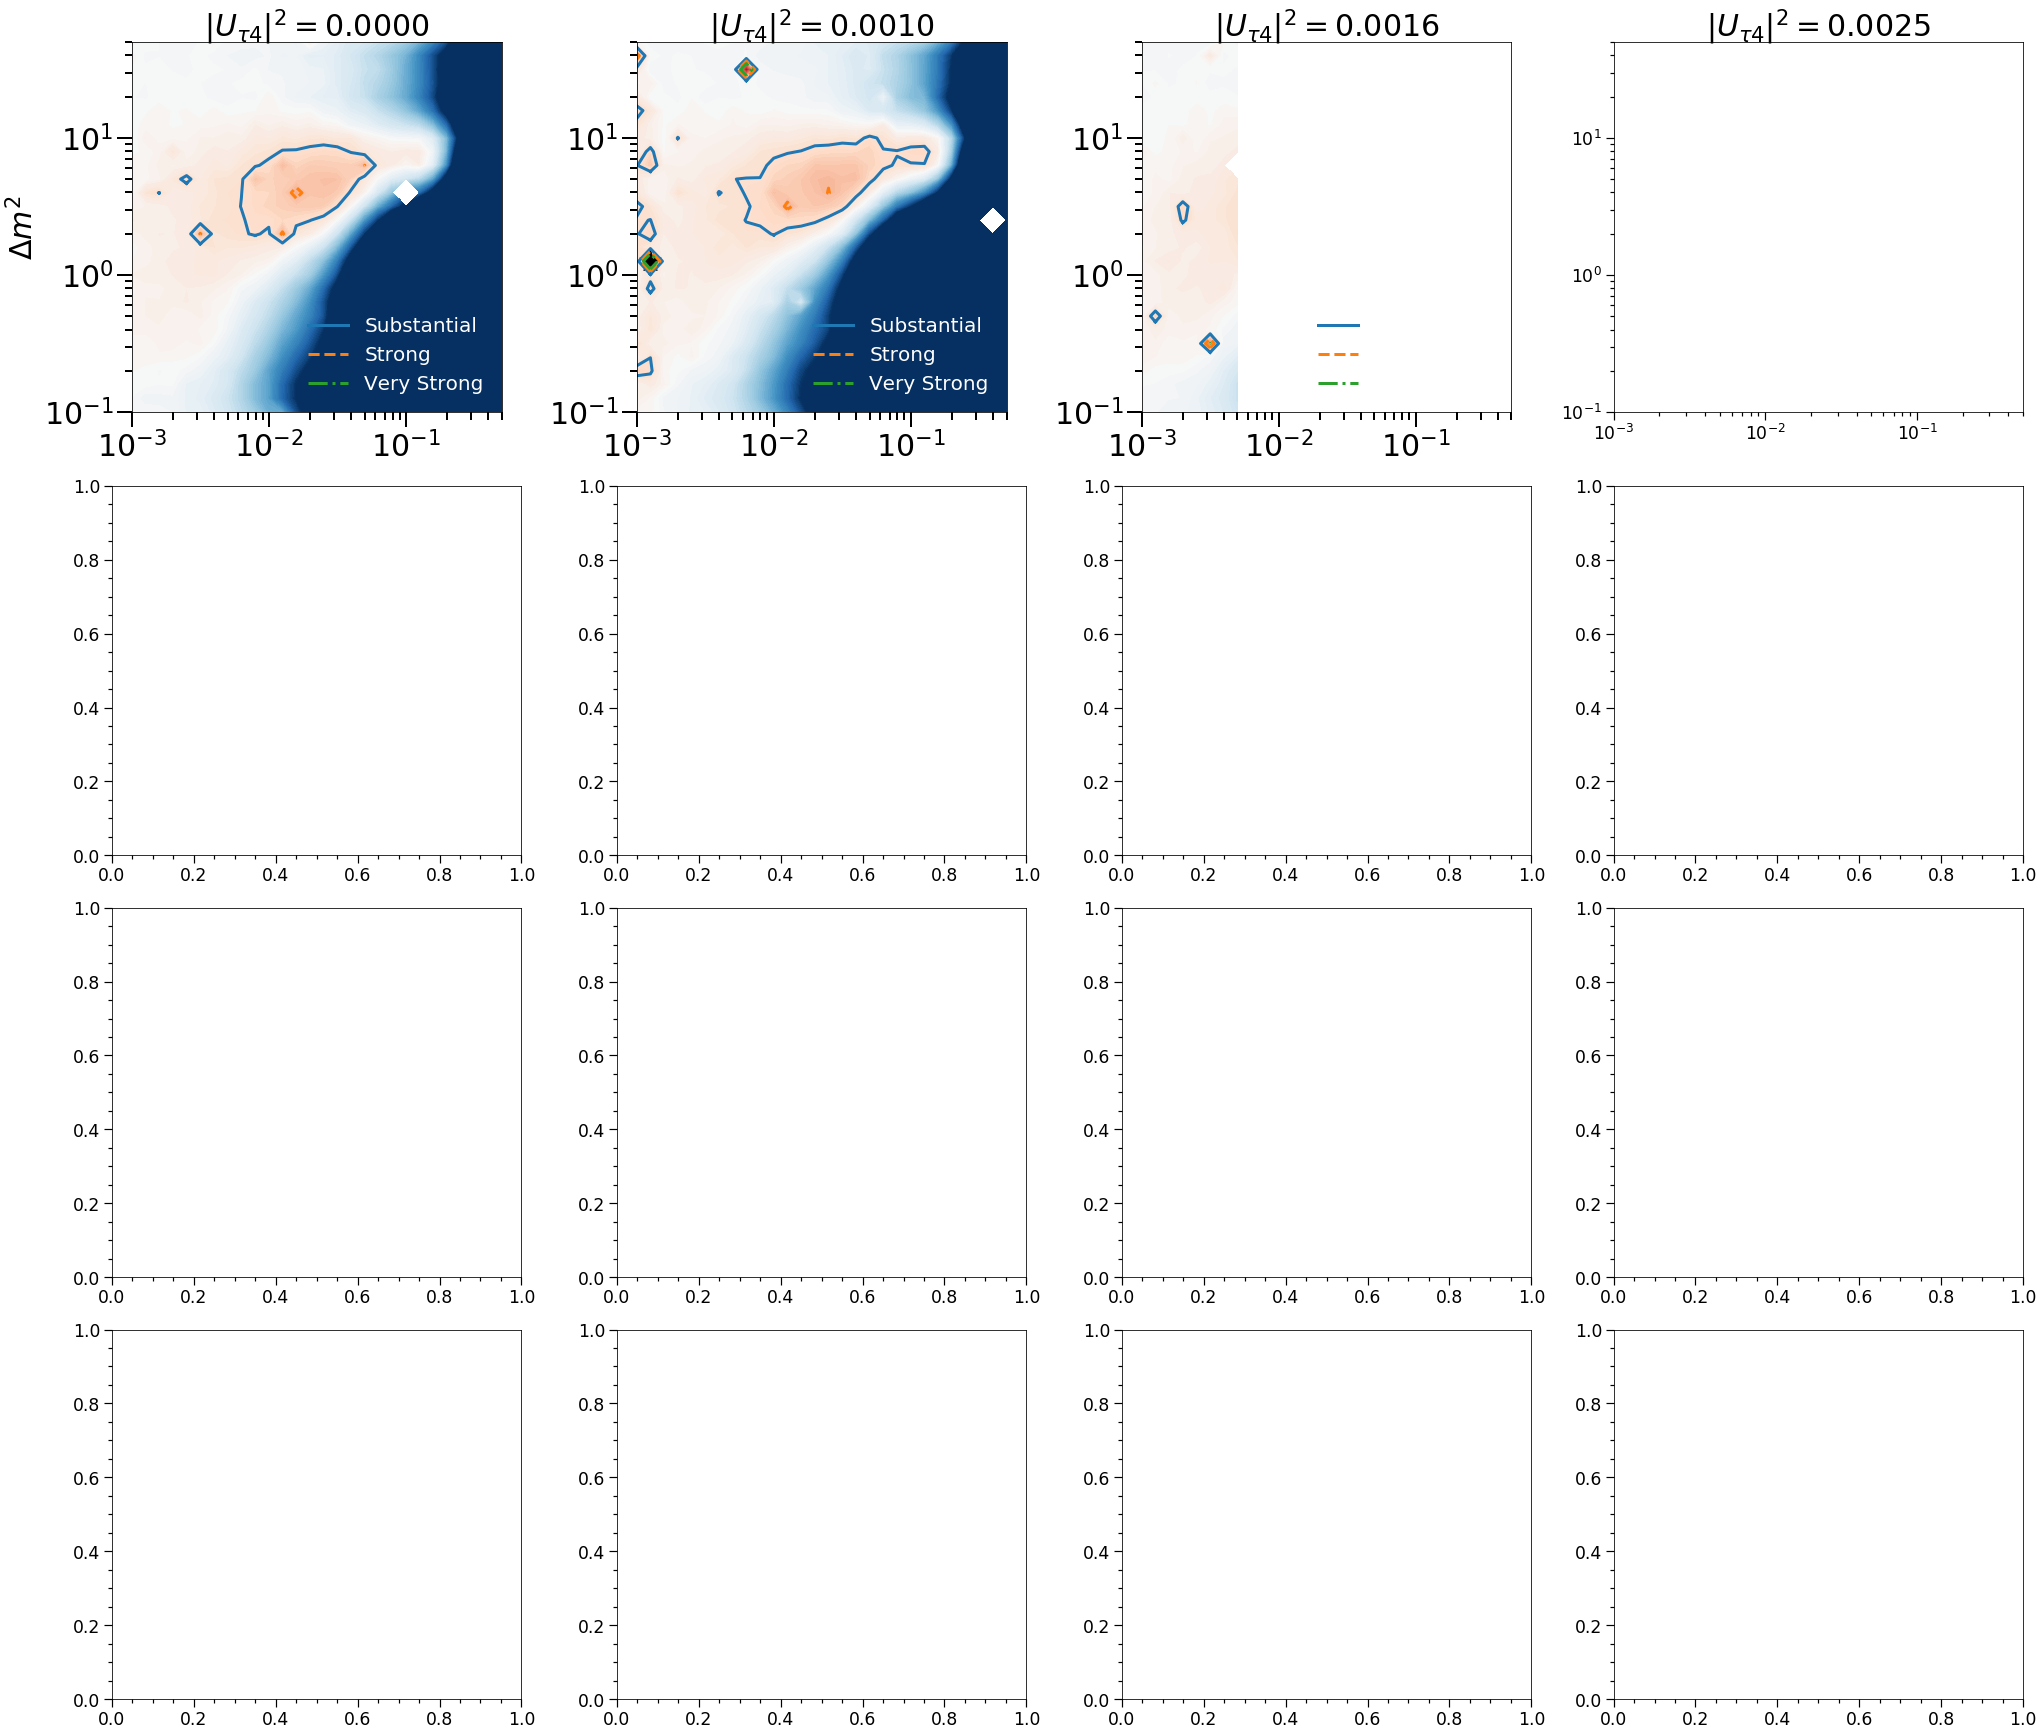

In [12]:
xscale = 1./0.85
size = 6
columns = 4
rows = int(np.ceil(len(Ut4sq_list)//columns))

x_lists = [Um4sq_list, utils.Um4sqtosin22th(Um4sq_list)]
x_labels = [r"$|U_{\mu 4}|^{2}$", r"$\sin^2 2 \theta_{24}$"]
filenames=["/home/adiaz/Plots/thesis/Bayes/Ut4sqslices_Um4sq.pdf", "/home/adiaz/Plots/thesis/Bayes/Ut4sqslices_sin22th.pdf"]

for x_list, x_label, x_max, filename in zip(x_lists, x_labels, x_maxs, filenames):
    fig, axes = plt.subplots(rows, columns, figsize=(xscale*size*columns,size*rows), constrained_layout=True)

    for i in range(rows*columns):
        ax = axes[i//columns][i%columns]

        if i > len(Ut4sq_list)-1:
            ax.axis('off')
            continue

        ax.set_title(r'$|U_{{\tau 4}}|^2 = {:.4f}$'.format(Ut4sq_list[i]), size = 30)
        ax.set_xlim(x_list.min(), x_list.max())
        ax.set_ylim(dm2_list.min(), dm2_list.max())


#         levels = [0.5,1,3./2.,2]
#         linestyles=['-', '--', '-.', ':']
#         scales = ['Substantial', 'Strong', 'Very Strong', 'Decisive']
        levels = [.5, 1,3./2.]
        linestyles=['-', '--', '-.']
        scales = ['Substantial', 'Strong', 'Very Strong']

        dEv=-(data[i,:,3]-data_null[3]) * np.log10(np.exp(1.))
        cf = utils.make_exclusion_colorful(dm2_list, x_list, dEv,
                  ax = ax, \
                            levels = np.linspace(-3,3,100), cmap='RdBu', extend='max')


        for level, linestyle, scale in zip(levels, linestyles, scales):

#             utils.make_exclusion(dm2_list, x_list, dEv, level, ax = ax, linestyle = linestyle)
            utils.make_exclusion(dm2_list, x_list, dEv, -level, ax = ax, linestyle = linestyle, label = scale)

        if i//columns == columns-1:
            ax.set_xlabel(x_label, size = 30)
        
        if i%columns == 0:
            ax.set_ylabel(r"$\Delta m^2$", size = 30)
            
            
        ax.tick_params(axis='both', which='major', labelsize=30)
        ax.tick_params(axis='both', which='major', length = 15, width = 2)
        ax.tick_params(axis='both', which='minor', length = 7.5, width = 2)
        ax.set_aspect('equal')
            
        
        if Ut4sq_list[i] == Ut4sq_max:
            ax.scatter(x_max, dm2_max, c = 'k', marker="*", s = 500)
#         plt.plot([-10,-10],[10,10],'-',label = 'Substancial' alpha=1,linewidth=(4))
#         plt.plot([-10,-10],[10,10],'--',label = 'Strong',, alpha=1,linewidth=(4))
#         plt.plot([-10,-10],[10,10],'-.',label = 'Very Strong', alpha=1,linewidth=(4))
#         plt.plot([-10,-10],[10,10],':',label = 'Decisive' alpha=1,linewidth=(4))
        l = ax.legend(loc = 'lower right', fontsize = 20)
        for text in l.get_texts():
            text.set_color("white")
    
    cbar = fig.colorbar(cf, ax=axes,ticks = np.linspace(-3,3,7), aspect = 40)
    cbar.set_label(r"$\log_{10}(\mathrm{Bayes Factor})$", size = 30)
    cbar.ax.tick_params(which='major', labelsize=30, length = 15, width = 2)
    cbar.ax.tick_params(which='minor', length = 7.5, width = 2)
    
#         ax.scatter(data_tighter[i,:,1][np.isfinite(data_tighter[i,:,3])], data_tighter[i,:,0][np.isfinite(data_tighter[i,:,3])], s =10)
    plt.draw()
#     fig.savefig(filename)
    plt.show()
#     break
    plt.clf()

In [11]:
a = np.loadtxt("/data/ana/SterileNeutrino/IC86/HighEnergy/Analysis/th34/Fits/FitToData/Bayes/evidence_tolerance_0.5_n_live_points_300_sampling_efficiency_0.5_Run2/Ut4sq_0.000000/errs.txt")

In [22]:
a.shape

(259,)

(array([  3., 123.,  42.,  20.,  12.,   7.,   7.,   7.,   4.,   5.]),
 array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ]),
 <a list of 10 Patch objects>)

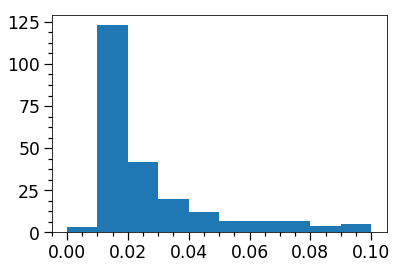

In [25]:
plt.hist(a, bins = np.linspace(0,.1,11) )

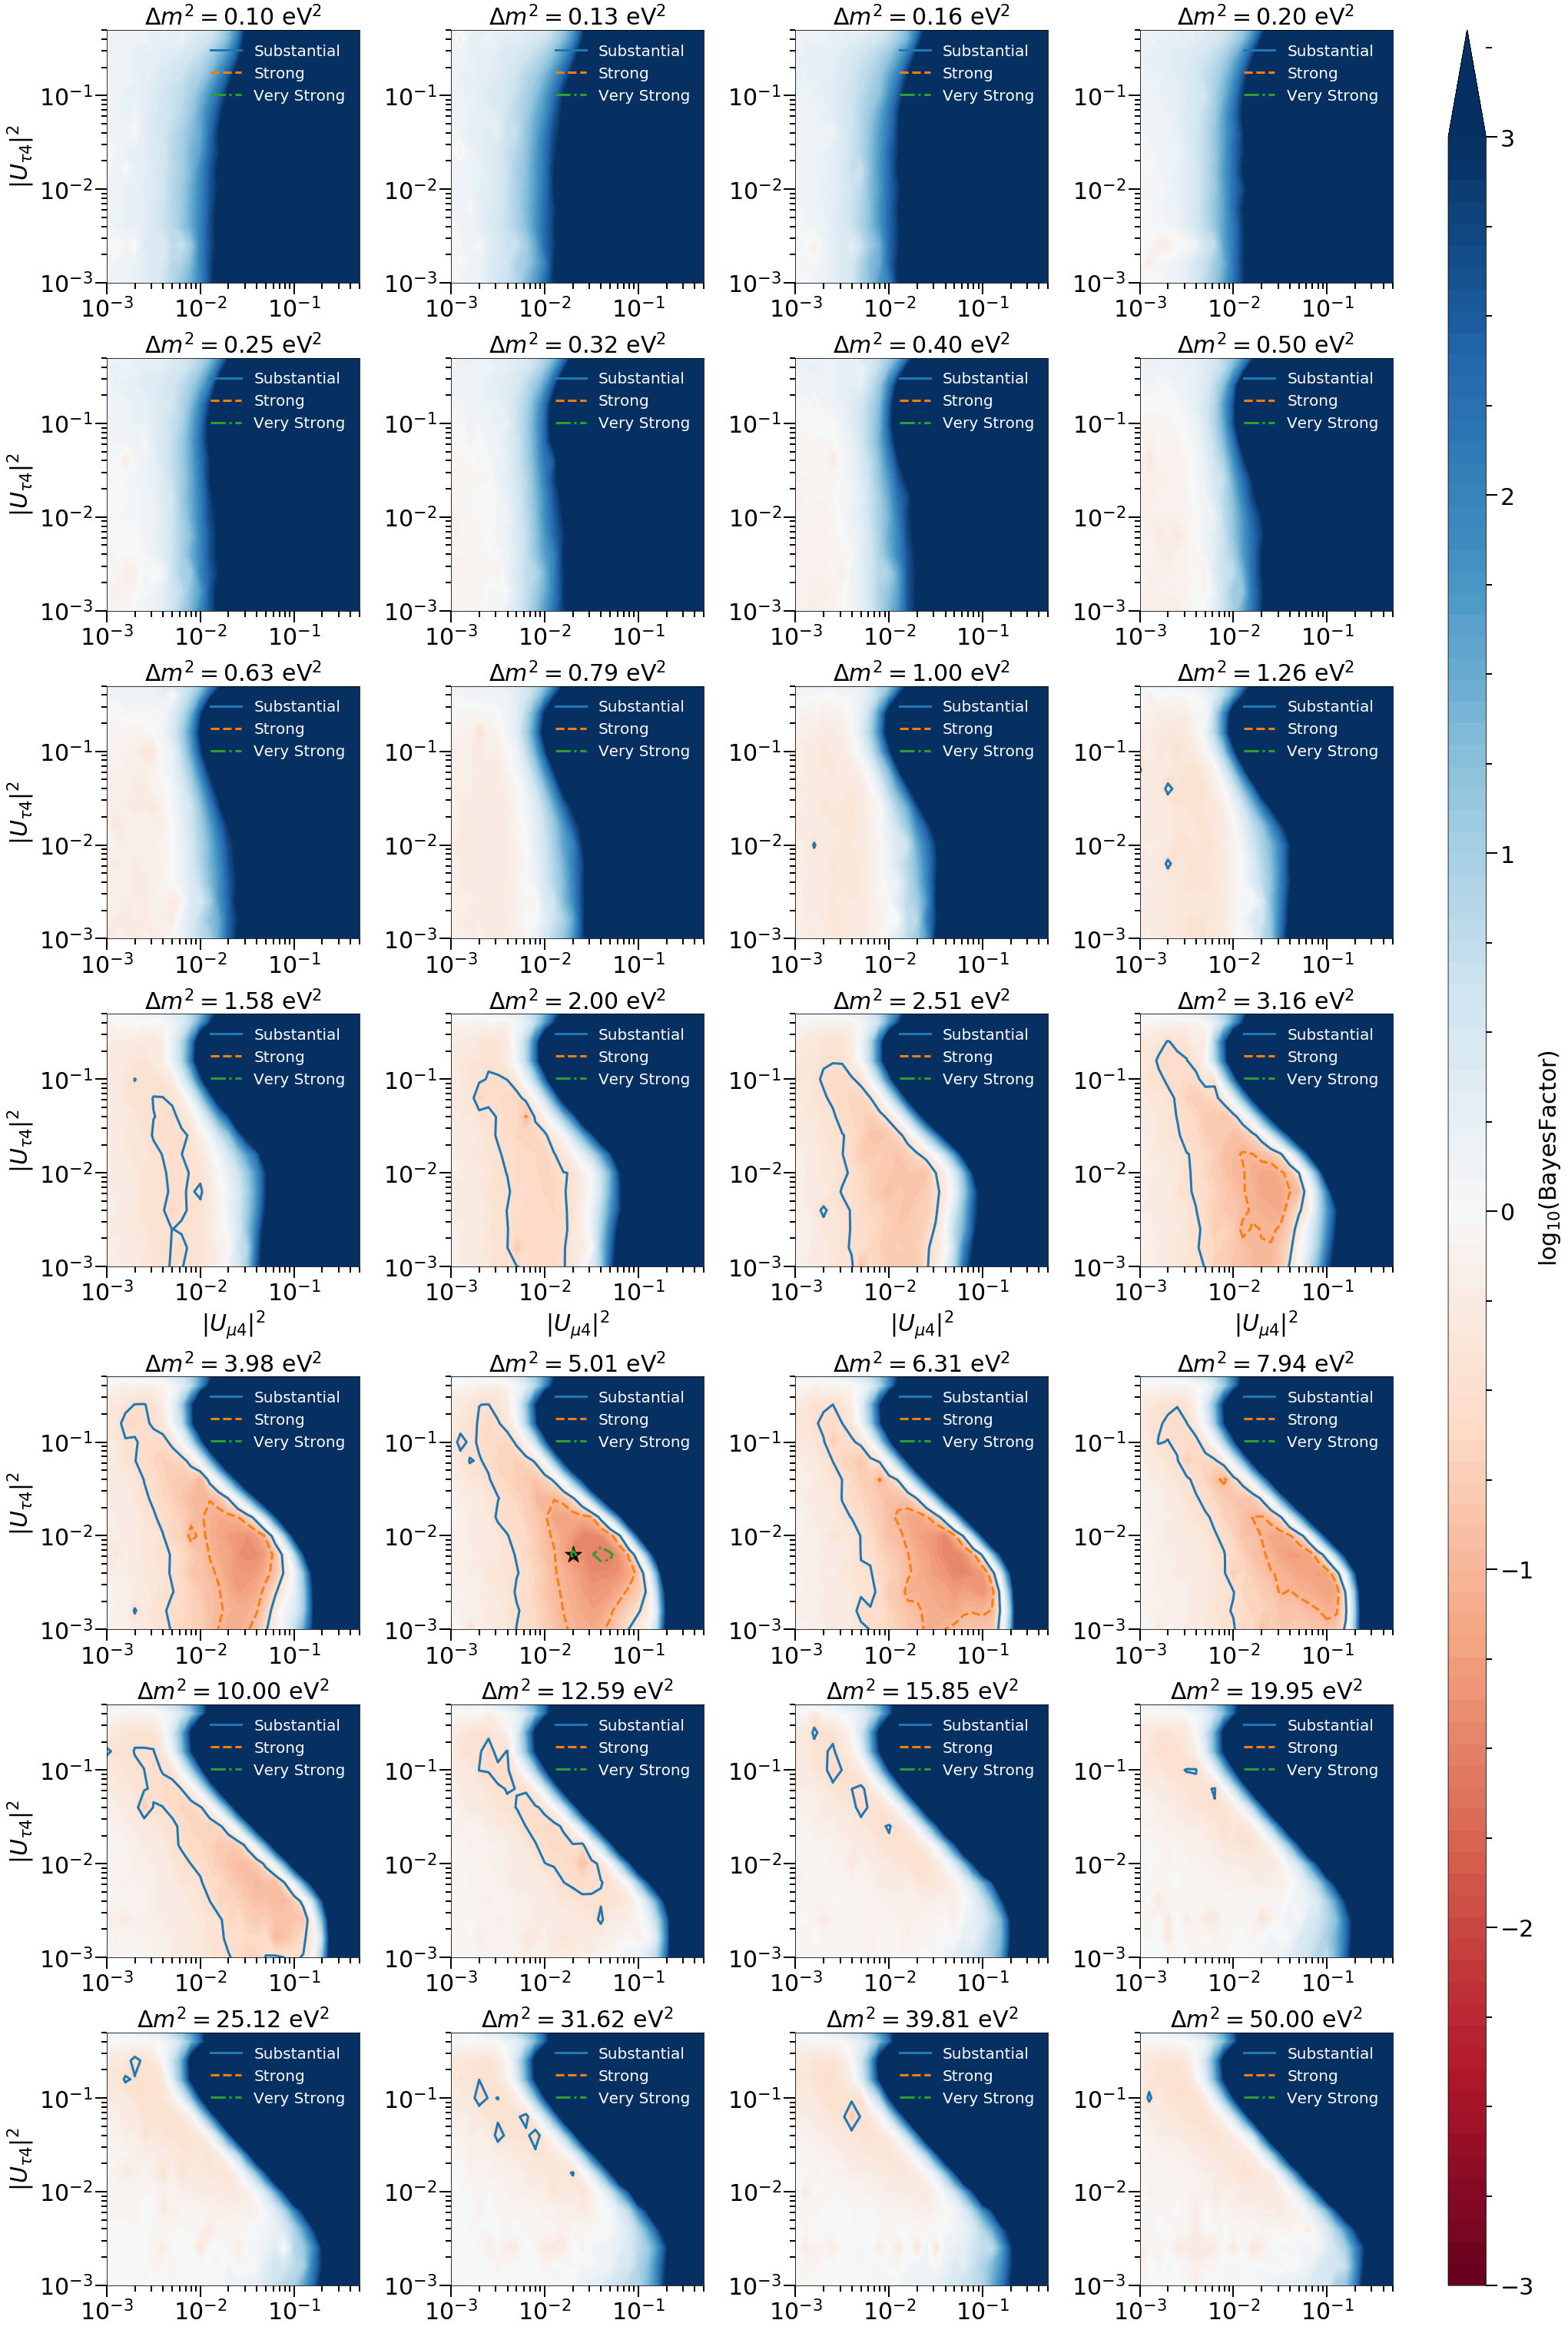

<Figure size 432x288 with 0 Axes>

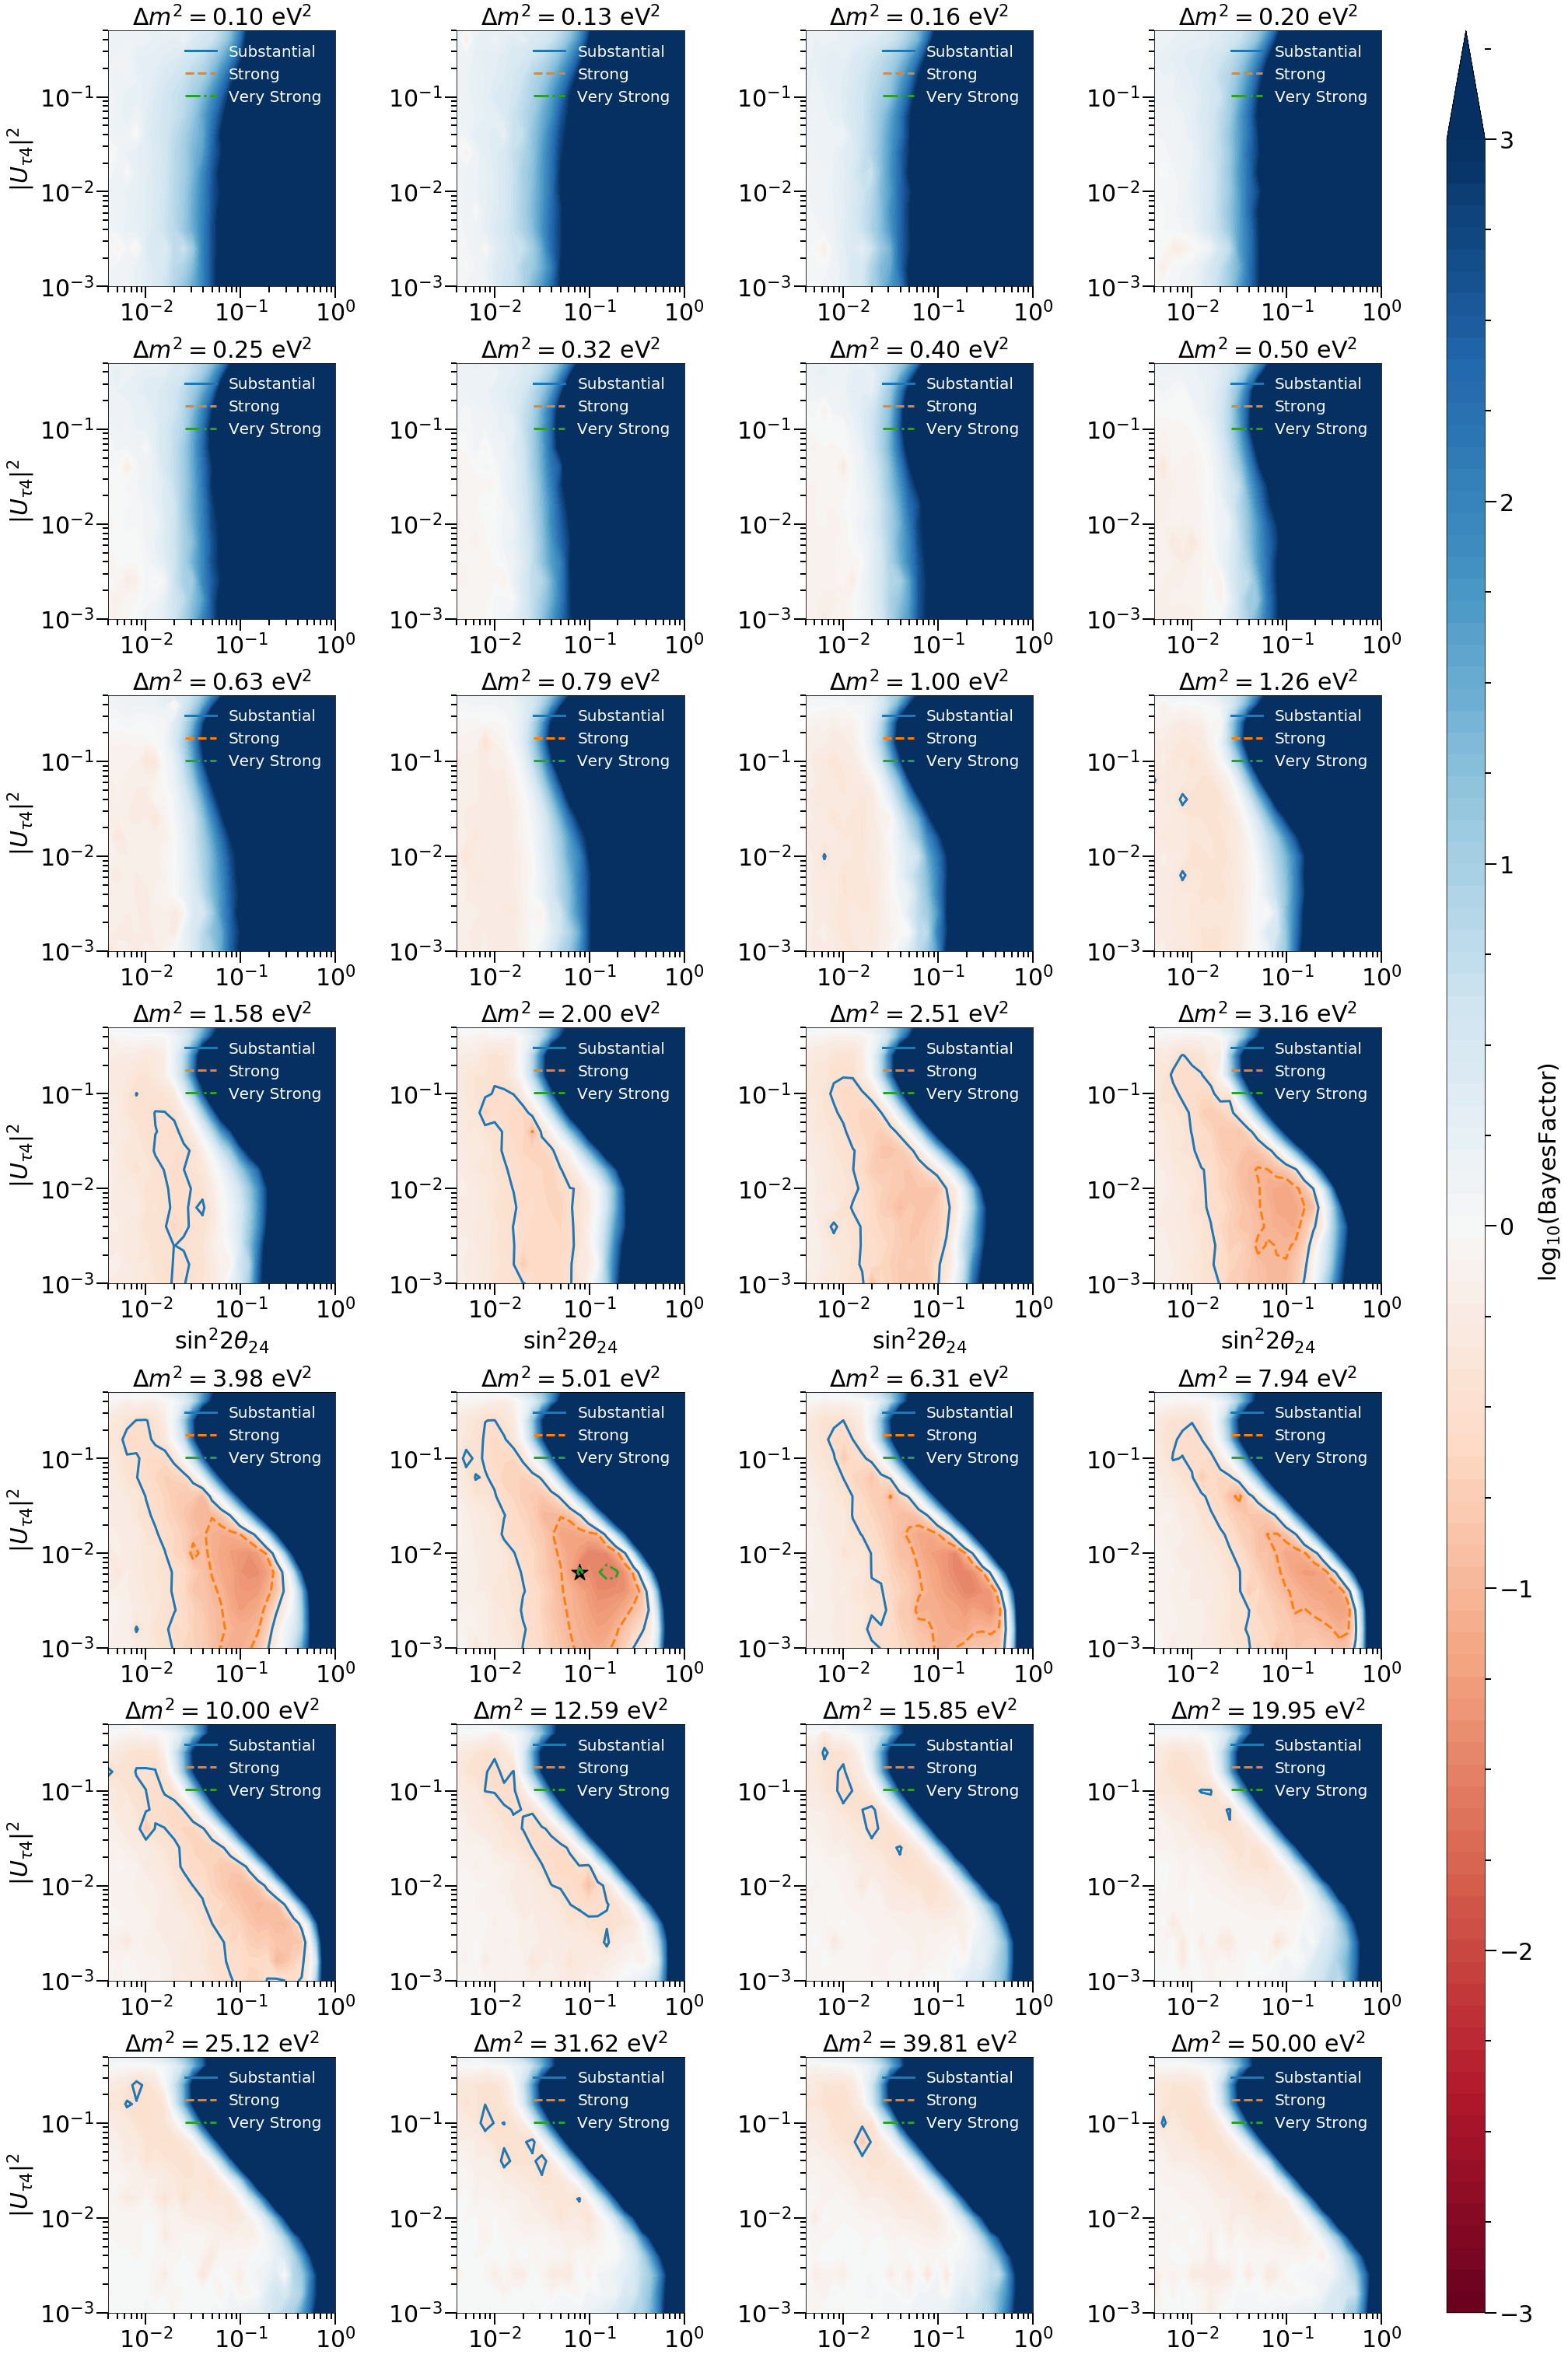

<Figure size 432x288 with 0 Axes>

In [19]:
xscale = 1./0.85
size = 6
columns = 4
rows = int(np.ceil(len(dm2_list)//columns))

x_lists = [Um4sq_list, utils.Um4sqtosin22th(Um4sq_list)]
x_labels = [r"$|U_{\mu 4}|^{2}$", r"$\sin^2 2 \theta_{24}$"]
filenames=["/home/adiaz/Plots/thesis/Bayes/dm2slices_Um4sq.pdf", "/home/adiaz/Plots/thesis/Bayes/dm2slices_sin22th.pdf"]

for x_list, x_label, x_max, filename in zip(x_lists, x_labels, x_maxs, filenames):
    fig, axes = plt.subplots(rows, columns, figsize=(xscale*size*columns,size*rows), constrained_layout=True)

    for i in range(rows*columns):
        ax = axes[i//columns][i%columns]
        if i > len(dm2_list)-1:
            ax.axis('off')
            continue

        ax.set_title(r"$\Delta m^2 = {:.2f}\ \mathrm{{eV}}^2$".format(dm2_list[i]), size = 30)
        ax.set_xlim(x_list.min(), x_list.max())
        ax.set_ylim(Ut4sq_list[1:].min(), Ut4sq_list.max())

        
        levels = [0.5,1,3./2.]
        linestyles=['-', '--', '-.']
        scales = ['Substantial', 'Strong', 'Very Strong']
        dEv=-(data[:,i*len(dm2_list):(i+1)*len(dm2_list),3]-data_null[3]) * np.log10(np.exp(1.))

        cf = utils.make_exclusion_colorful(Ut4sq_list, x_list, dEv.flatten(),
                  ax = ax, \
                            levels = np.linspace(-3,3,100), cmap='RdBu', extend='max')


        for level, linestyle, scale in zip(levels, linestyles, scales):
#             utils.make_exclusion(Ut4sq_list, x_list, dEv.flatten(), level, ax = ax, linestyle = linestyle)
            utils.make_exclusion(Ut4sq_list, x_list, dEv.flatten(), -level, ax = ax, linestyle = linestyle, label = scale)

        if i//columns == columns-1:
            ax.set_xlabel(x_label, size = 30)
        
        if i%columns == 0:
            ax.set_ylabel(r"$|U_{\tau4}|^2$", size = 30)
            
        ax.tick_params(axis='both', which='major', labelsize=30)
        ax.tick_params(axis='both', which='major', length = 15, width = 2)
        ax.tick_params(axis='both', which='minor', length = 7.5, width = 2)
        ax.set_aspect('equal')

        l=ax.legend(loc = 'upper right', fontsize = 20)
        
        for text in l.get_texts():
            text.set_color("white")
        
        if dm2_list[i] == dm2_max:
            ax.scatter(x_max, Ut4sq_max, c = 'k', marker="*", s = 500)


    cbar = fig.colorbar(cf, ax=axes,ticks = np.linspace(-3,3,7), aspect = 40)
    cbar.set_label(r"$\log_{10}(\mathrm{Bayes Factor})$", size = 30)
    cbar.ax.tick_params(which='major', labelsize=30, length = 15, width = 2)
    cbar.ax.tick_params(which='minor', length = 7.5, width = 2)
    
    plt.draw()
    fig.savefig(filename)
    plt.show()
    plt.clf()

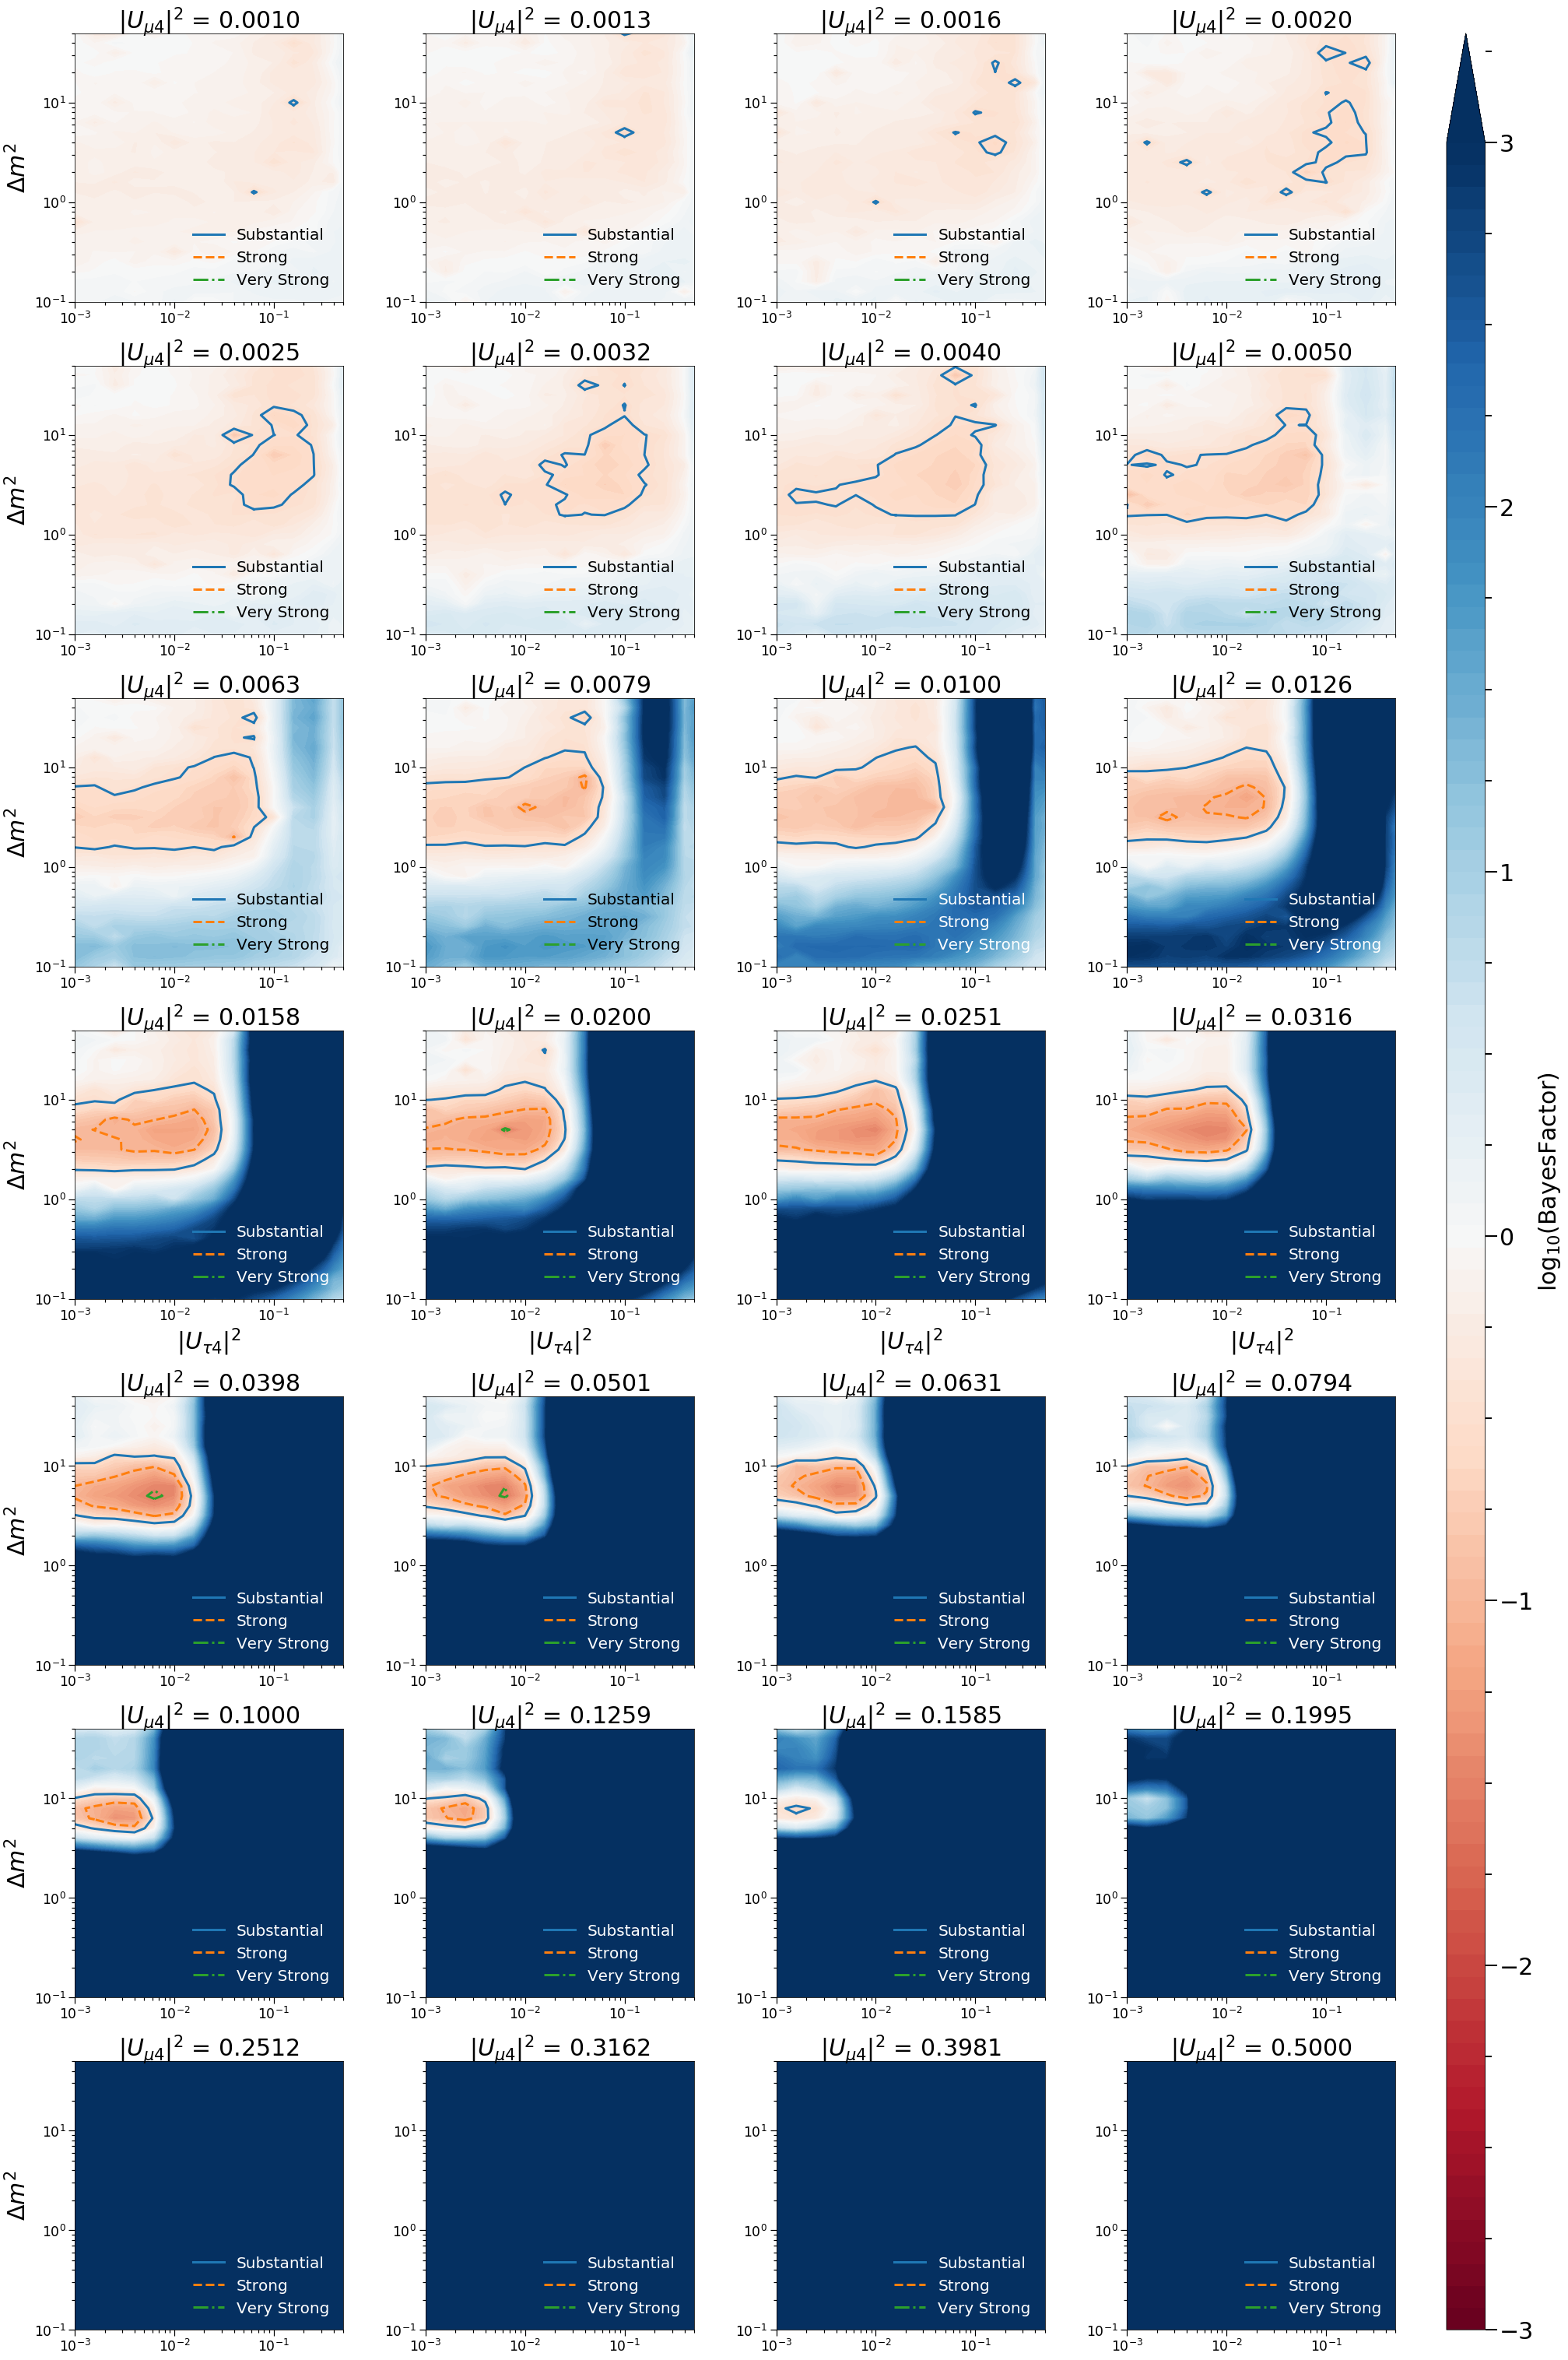

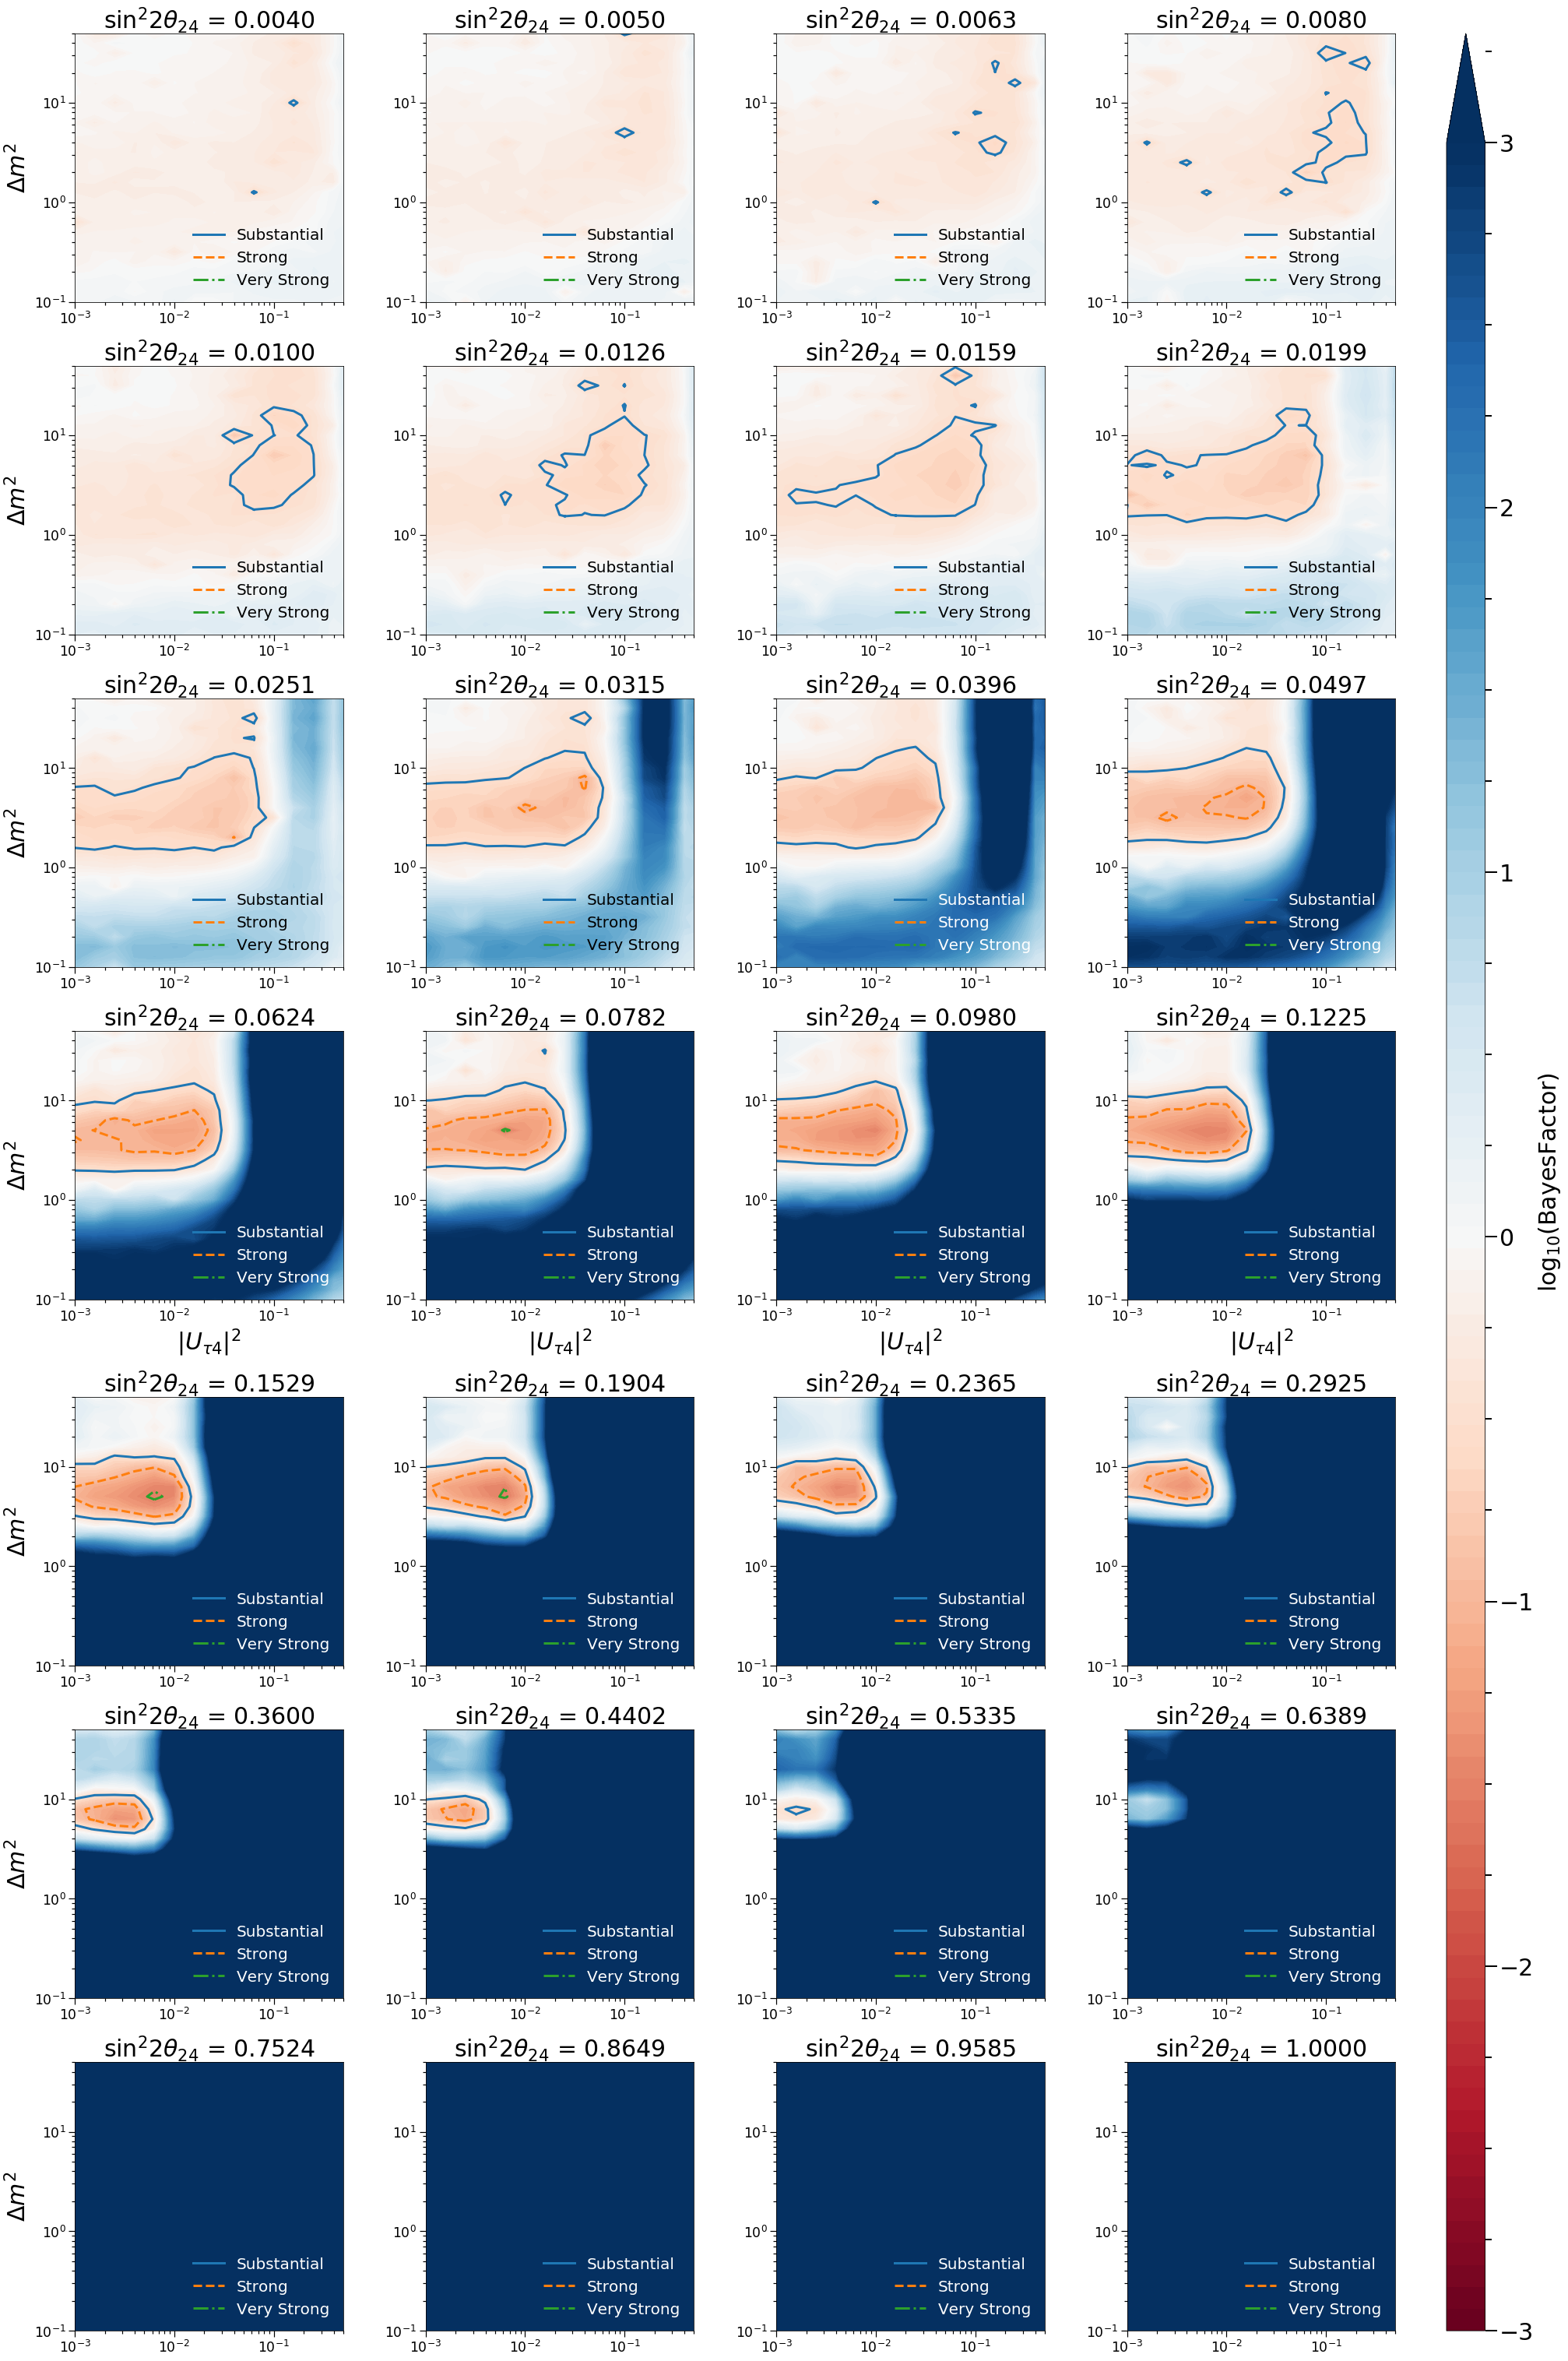

In [20]:
xscale = 1./0.85
size = 6
columns = 4
rows = int(np.ceil(len(Um4sq_list)//columns))

z_lists = [Um4sq_list, utils.Um4sqtosin22th(Um4sq_list)]
z_labels = [r"$|U_{\mu 4}|^{2}$", r"$\sin^2 2 \theta_{24}$"]
filenames=["/home/adiaz/Plots/thesis/Bayes/Um4sqslices_Um4sq.pdf", "/home/adiaz/Plots/thesis/Bayes/sin22thslices_sin22th.pdf"]
z_maxs = [Um4sq_max, utils.Um4sqtosin22th(Um4sq_max)]

for z_list, z_label, z_max, filename in zip(z_lists, z_labels, z_maxs, filenames):
    fig, axes = plt.subplots(rows, columns, figsize=(xscale*size*columns,size*rows), constrained_layout=True)
    
    for i in range(rows*columns):

        ax = axes[i//columns][i%columns]

        if i > len(z_list)-1:
            ax.axis('off')
            continue

        x_list = Ut4sq_list
        ax.set_title(z_label + r" = {:.4f}".format(z_list[i]), fontsize = 30)
        ax.set_xlim(x_list[1:].min(), x_list.max())
        ax.set_ylim(dm2_list.min(), dm2_list.max())

        ax.set_aspect('equal')
        levels = [0.5,1,3./2.]
        linestyles=['-', '--', '-.']
        scales = ['Substantial', 'Strong', 'Very Strong']

        dEv=-(data[:,i::len(z_list),3]-data_null[3]).T.flatten() * np.log10(np.exp(1.))

        cf = utils.make_exclusion_colorful(dm2_list, x_list, dEv,
                  ax = ax, \
                            levels = np.linspace(-3,3,100), cmap='RdBu', extend='max')


        for level, linestyle, scale in zip(levels, linestyles,scales):

#             utils.make_exclusion(dm2_list, x_list, dEv, level, ax = ax, linestyle = linestyle)
            utils.make_exclusion(dm2_list, x_list, dEv, -level, ax = ax, linestyle = linestyle, label=scale)

        if i//columns == columns-1:
            ax.set_xlabel(r"$|U_{\tau4}|^2$", size = 30)
        
        if i%columns == 0:
            ax.set_ylabel(r"$\Delta m^2$", size = 30)


        l=ax.legend(loc = 'lower right', fontsize = 20)
        
        if i < 10:
            for text in l.get_texts():
                text.set_color("black")
        else:
            for text in l.get_texts():
                text.set_color("white")
#         if z_list[i] == z_max:
#             ax.scatter(Ut4sq_max, dm2_max, c = 'k', marker="*", s = 2000)

    cbar = fig.colorbar(cf, ax=axes,ticks = np.linspace(-3,3,7), aspect = 40)
    cbar.set_label(r"$\log_{10}(\mathrm{Bayes Factor})$", size = 30)
    cbar.ax.tick_params(which='major', labelsize=30, length = 15, width = 2)
    cbar.ax.tick_params(which='minor', length = 7.5, width = 2)
    
    plt.draw()

    fig.savefig(filename)

    plt.show()
#     plt.clf()

In [18]:
(llh_max - data_null[3])*np.log10(np.e)

2.1886810268473296

In [19]:
data[:,:,3]

array([[-2930.42553977, -2929.60915775, -2930.42099715, ...,
        -2944.37420774, -2949.49928112, -2953.57565579],
       [-2930.14519621, -2930.27027354, -2930.39081694, ...,
        -2942.26621362, -2948.04834355, -2953.22588179],
       [-2930.49432917, -2930.63955561, -2930.62156379, ...,
        -2941.72090999, -2947.69913867, -2953.32879295],
       ...,
       [-2930.72429684, -2930.74156304, -2930.90531608, ...,
        -3643.49061123, -3928.68569724, -3713.16268137],
       [-2930.61141453, -2930.76513934, -2930.77838519, ...,
        -3754.32121076, -3578.58236732, -3168.55696702],
       [-2930.68010598, -2930.67033743, -2930.61669082, ...,
        -3383.88879474, -3148.60617677, -2945.14387057]])

  analysing data from /data/ana/SterileNeutrino/IC86/HighEnergy/Analysis/th34/Fits/FitToData/Bayes/evidence_tolerance_0.5_n_live_points_300_sampling_efficiency_0.5_Run2/Ut4sq_0.006310/5.011872_0.141728_0.080324..txt
Correlation matrix

['Normalization ($\\Phi_{\\mathrm{conv.}}$)', 'Spectral shift ($\\Delta\\gamma_{\\mathrm{conv.}}$)', 'Atm. Density', 'Barr WP', 'Barr WM', 'Barr YP', 'Barr YM', 'Barr ZP', 'Barr ZM', 'DOM Efficiency', 'Hole Ice (p$_2$)', 'Ice Gradient 0', 'Ice Gradient 1', 'Normalization ($\\Phi_{\\mathrm{astro.}}$)  ', 'Spectral shift ($\\Delta\\gamma_{\\mathrm{astro.}}$)', 'Cross section $\\sigma_{\\nu_\\mu}$', 'Cross section $\\sigma_{\\overline{\\nu}_\\mu}$ ', 'Kaon Energy Loss $\\sigma_{KA}$']
1.00	-0.57	-0.60	-0.09	-0.09	-0.56	-0.16	-0.06	-0.08	0.22	0.01	0.23	0.16	-0.12	-0.07	-0.01	0.00	0.33
-0.57	1.00	0.58	-0.12	0.02	0.11	0.16	0.10	0.14	-0.08	-0.18	-0.19	-0.63	0.43	0.25	-0.01	-0.01	0.07
-0.60	0.58	1.00	0.05	0.01	0.23	-0.02	-0.03	0.04	0.11	0.12	0.07	0.02	0.26	0.35	

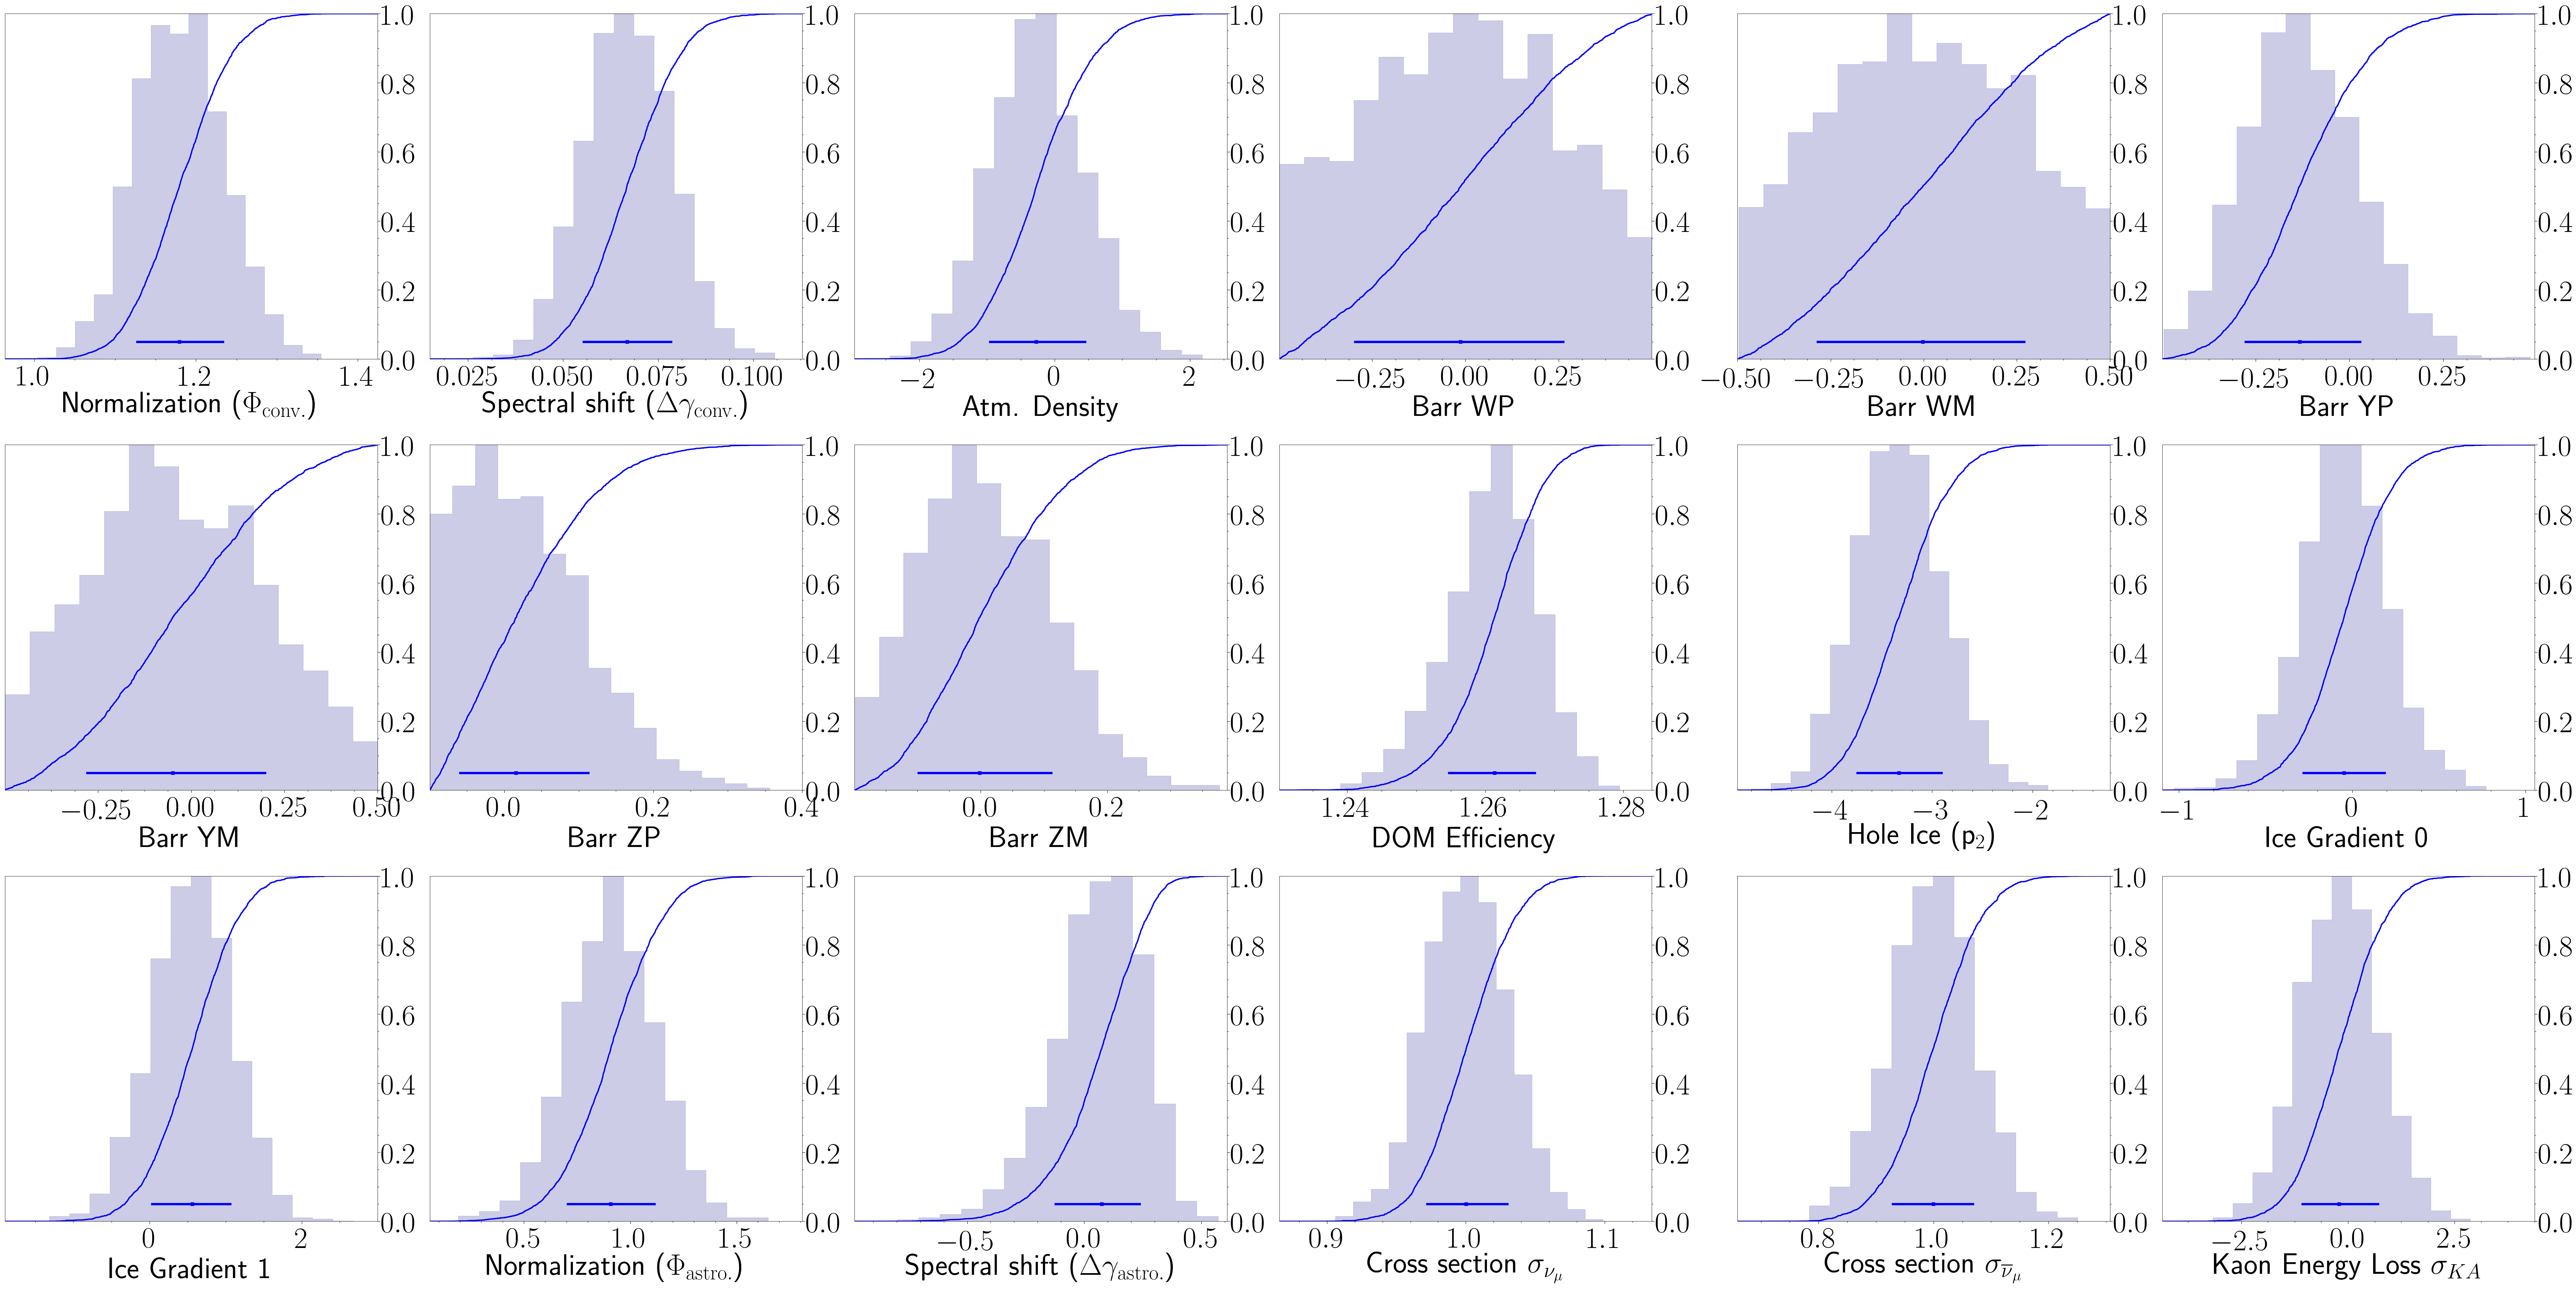

In [29]:
# prefix_1 = '/data/ana/SterileNeutrino/IC86/HighEnergy/Analysis/th34/Fits/FitToData/Bayes/evidence_tolerance_0.04_n_live_points_600_sampling_efficiency_0.3/Ut4sq_0.006310/3.981072_0.178779_0.080807.'
prefix_1 = '/data/ana/SterileNeutrino/IC86/HighEnergy/Analysis/th34/Fits/FitToData/Bayes/evidence_tolerance_0.5_n_live_points_300_sampling_efficiency_0.5_Run2/Ut4sq_0.006310/5.011872_0.141728_0.080324.'

parameters = [r"Normalization ($\Phi_{\mathrm{conv.}}$)",
              r"Spectral shift ($\Delta\gamma_{\mathrm{conv.}}$)",
              r"Atm. Density",
              r"Barr WP",
              r"Barr WM", r"Barr YP", r"Barr YM", r"Barr ZP", r"Barr ZM",
              r"DOM Efficiency", r"Hole Ice (p$_2$)", r"Ice Gradient 0", r"Ice Gradient 1",
              r"Normalization ($\Phi_{\mathrm{astro.}}$)  ",r"Spectral shift ($\Delta\gamma_{\mathrm{astro.}}$)",
              r"Cross section $\sigma_{\nu_\mu}$",r"Cross section $\sigma_{\overline{\nu}_\mu}$ ",r"Kaon Energy Loss $\sigma_{KA}$"]

import matplotlib
# font = {'family': 'serif',
#                     'serif':  'Computer Modern Roman',
#                     'weight': 200,
#                     'size':   80}

# matplotlib.rc('font', **font)

plt.rc('text', usetex=True)

n_params = len(parameters)
p0_low =  [0.1,-0.25,-3.0,-0.5,-0.5,-0.5,-0.5,-0.1,-0.2,1.23,-5.0,-3.,-3.,0,-1,0.5,0.5,-5]
p0_high = [2.0, 0.25, 3.0, 0.5, 0.5, 0.5, 0.5, 0.4, 0.4,1.35, 2.0, 3., 3.,2, 1,1.5,1.5,5]

assert(len(p0_low) == len(p0_high) == len(parameters) == n_params);

a_1 = pymultinest.Analyzer(n_params = n_params, outputfiles_basename = prefix_1)
s_1 = a_1.get_stats()

posterior_sample_1 = a_1.get_equal_weighted_posterior()

weight_1 = 1./float(len(posterior_sample_1))

mu_1 = {}
for ni in range(n_params):
    mu_1[ni] = 0.0
    for params in posterior_sample_1:
        mu_1[ni] += params[ni]*weight_1

        
var_1 = {}
for ni in range(n_params):
    var_1[ni] = 0.0
    for params in posterior_sample_1:
        var_1[ni] += (params[ni] - mu_1[ni])**2*weight_1

        
correlation_1 = {}
for ni in range(n_params):
    for nj in range(n_params):
        correlation_1[(ni,nj)] = 0.0
        sigma_product = np.sqrt(var_1[ni])*np.sqrt(var_1[nj])
        for params in posterior_sample_1:
            correlation_1[(ni,nj)] += weight_1*(params[ni] - mu_1[ni])*(params[nj] - mu_1[nj])/(sigma_product)


COR_1 = []
for ni in range(n_params):
    row = []
    for nj in range(n_params):
        row.append(correlation_1[(ni,nj)])
    COR_1.append(row)


print('Correlation matrix\n')
print(parameters)
print('\n'.join(['\t'.join(['{:.2f}'.format(item) for item in row])
          for row in COR_1]))
print('\n')

s_1['correlation'] = COR_1
np.savetxt(prefix_1 + 'correlation.txt', s_1['correlation'])



json.dump(s_1, open(prefix_1 + 'stats.json', 'w'), indent=4)

print('  marginal likelihood:')
print('    ln Z = %.1f +- %.1f' % (s_1['global evidence'], s_1['global evidence error']))
print('  parameters:')
'''
for p, m in zip(parameters, s['marginals']):
    lo, hi = m['1sigma']
    med = m['median']
    sigma = (hi - lo) / 2
    i = max(0, int(-np.floor(np.log10(sigma))) + 1)
    fmt = '%%.%df' % i
    fmts = '\t'.join(['%-15s   &  ' + fmt + " $\\pm$ " + fmt+"\\\\"])
    print(fmts % (p, med, sigma))
'''
print('')
for p, m in zip(parameters, s_1['marginals']):

    if p == "DOM Efficiency":
        print("\multicolumn{2}{c}{\\textbf{Detector parameters}}\\\\")
        print("\hline")
    if p == "Normalization ($\Phi_{\mathrm{conv.}}$)":
        print("\multicolumn{2}{c}{\\textbf{Conventional Flux parameters}}\\\\")
        print("\hline")
    if p == "Normalization ($\Phi_{\mathrm{astro.}}$)":
        print("\multicolumn{2}{c}{\\textbf{Astrophysical Flux parameters}}\\\\")
        print("\hline")
    if r"Cross section $\sigma_{\nu_\mu}$" in p:
        print("\multicolumn{2}{c}{\\textbf{Cross sections}}\\\\")
        print("\hline")

    lo, hi = m['1sigma']
    med = m['median']
    sigma = (hi - lo) / 2
    i = max(0, int(-np.floor(np.log10(sigma))) + 1)
    fmt = '%%.%df' % i
    fmts = '\t'.join(['%-15s   &  ' + fmt + " $\\pm$ " + fmt+"\\\\"])
    print(fmts % (p, med, sigma))
    print("\hline")
print('')

print('creating marginal plot ...')
p_1      = pymultinest.PlotMarginal(a_1)
values_1 = a_1.get_equal_weighted_posterior()
assert n_params == len(s_1['marginals'])

modes  = s_1['modes']
nbins  = 15

fontsize= 90
fig, axes = plt.subplots(3,6, figsize=(6*n_params, 3*n_params), constrained_layout=True)

for i in range(n_params):
    oldax = axes.flatten()[i]
    print(i)
    #plt.subplot(n_params, n_params, i + 1)
#     plt.subplot(3, 6, i + 1)
    oldax.set_xlabel(parameters[i],fontsize = fontsize)

    m_1 = s_1['marginals'][i]

    oldax.set_xlim(m_1['5sigma'])

#     oldax = plt.gca()
    #print(np.shape(values_1[:,i]))
    #print(len(values_1[:,i]))
    x_1,w_1, patches = oldax.hist(values_1[:,i], bins=nbins,weights = np.ones(len(values_1[:,i]))*1./len(values_1[:,i]), edgecolor='darkblue', color='darkblue', histtype='stepfilled', alpha=0.2)
    
    oldax.set_ylim(0, x_1.max())
    
#     newax = plt.gcf().add_axes(oldax.get_position(), sharex = oldax, frameon=False)
    newax = oldax.twinx()
    p_1.plot_marginal(i, ls='-', color='blue', linewidth=4)
    newax.set_ylim(0, 1)
    ylim = newax.get_ylim()
    y = ylim[0] + 0.05*(ylim[1] - ylim[0])
    
    center = m_1['median']
    low1, high1 = m_1['1sigma']
    newax.errorbar(x=center, y=y,
        xerr=np.transpose([[center - low1, high1 - center]]),
        color='blue', linewidth=7, marker='s')
    
    oldax.tick_params(axis='x', labelsize= fontsize)
    newax.tick_params(axis='y', labelsize= fontsize)
    oldax.set_yticks([])
    #newax.set_ylabel("Probability",fontsize =fontsize)
    ylim = oldax.get_ylim()
    newax.set_xlim(m_1['5sigma'])
    #plt.close()
    #break
    



# plt.tight_layout()

# png_name = '/home/adiaz/Plots/Bayes/posterior.png'
pdf_name = '/home/adiaz/Plots/Bayes/posterior.pdf'
# print(png_name)

#plt.savefig(prefix_1+'pdf', format='pdf', dpi=200, bbox_inches='tight')
# plt.savefig(png_name, dpi=100, bbox_inches='tight')
plt.savefig(pdf_name, bbox_inches='tight')

plt.show()

# plt.close('all')

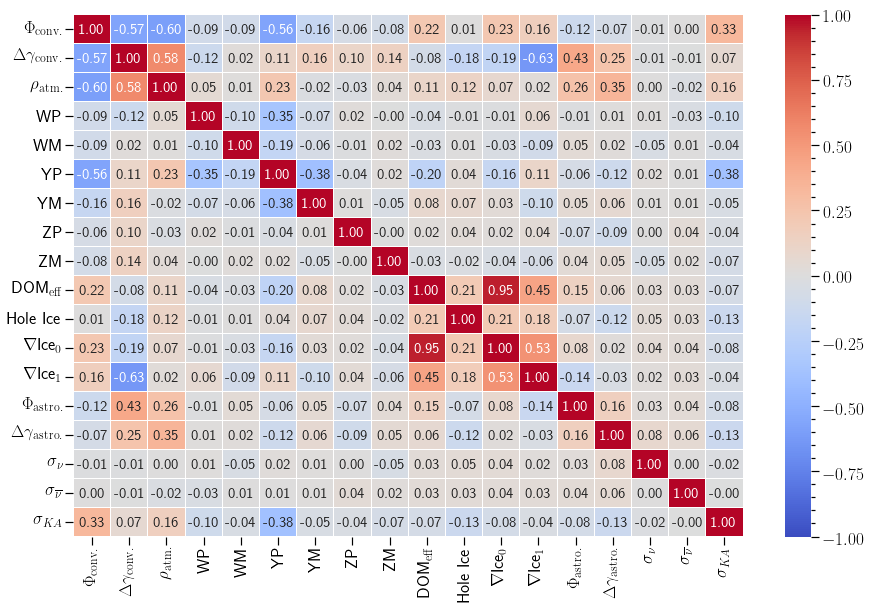

In [31]:
import seaborn as sns
infile = prefix_1+'correlation.txt'
# infile = '/data/user/saxani/Bayes/BayesNarrow2/50.000000_0.039758_0.341393.correlation.txt'

a = np.loadtxt(infile)

p0_names = [r"$\Phi_{\mathrm{conv.}}$", r"$\Delta \gamma_{\mathrm{conv.}}$",
        r"$\rho_{\mathrm{atm.}}$",
        r"WP", r"WM", r"YP", r"YM", r"ZP", r"ZM",
        r"DOM$_{\mathrm{eff}}$", r"Hole Ice", 
        r"$\nabla$Ice$_0$", r"$\nabla$Ice$_1$",
        r"$\Phi_{\mathrm{astro.}}$", r"$\Delta \gamma_{\mathrm{astro.}}$",
        r"$\sigma_\nu$",r"$\sigma_{\overline{\nu}}$",r"$\sigma_{KA}$"]

fig, (ax) = plt.subplots(1, 1, figsize=(15,9))

hm = sns.heatmap(a, 
                 ax=ax,           # Axes in which to draw the plot, otherwise use the currently-active Axes.
                 cmap="coolwarm", # Color Map.
                 #square=True,    # If True, set the Axes aspect to “equal” so each cell will be square-shaped.
                 annot=True, 
                 fmt='.2f',       # String formatting code to use when adding annotations.
                 annot_kws={"size": 15},
                 linewidths=.05,
                 xticklabels = p0_names ,
                 yticklabels = p0_names, vmin =-1, vmax =1)
ax.minorticks_off()
fig.subplots_adjust(top=0.93)
'''
fig.suptitle('Correlation between systematics (Asimov @ Null)', 
              fontsize=32, 
              fontweight='bold')
'''
# png_name =  '/home/adiaz/Plots/Bayes/correlation.png'
# print(png_name)

pdf_name =  '/home/adiaz/Plots/Bayes/correlation.pdf'
plt.savefig(pdf_name, bbox_inches='tight')
plt.show()


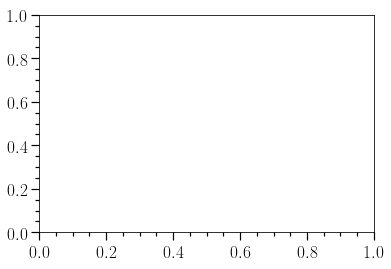

In [20]:
fig, ax = plt.subplots()

In [21]:
fig.dpi

72.0

In [ ]:
100